# Clustering Lab — see every claim from the README with your own eyes

This notebook is the hands-on companion to [`../README.md`](../README.md). It uses the ready-made implementations in
**scikit-learn** and **SciPy**; the sister notebook [`clustering_from_scratch.ipynb`](clustering_from_scratch.ipynb)
rebuilds the same algorithms in NumPy. Every lab has a short goal, the code, the numbers/plots, and a
**"How to read this"** box.

**How to use it**

1. Run the first code cell (imports and two small helpers). After that, run the labs in order (`Shift + Enter` cell by
   cell, or **Run All**, about 10 seconds). Labs only reuse things from earlier cells, so top-to-bottom always works.
2. Read the "How to read this" box *after* looking at the output: try to guess first.
3. Change the numbers marked `# <- try changing this` and re-run to build intuition.

**One score used everywhere:** the data in these labs comes with the "true" groups it was generated from, which a real
clustering problem doesn't have. We use them only to *grade* a result with the **adjusted Rand index (ARI)**: 1 = the
clusters match the true groups exactly, 0 = no better than random labels (it can dip slightly below 0). Lab 11 shows
the scores you use when there are no true groups.

| Part | Labs | What it shows |
|---|---|---|
| **[A. k-means](#part-a)** | [1](#lab-1) · [2](#lab-2) · [3](#lab-3) · [4](#lab-4) | how it moves, why the start matters, choosing k, where it fails |
| **[B. Hierarchical clustering](#part-b)** | [5](#lab-5) · [6](#lab-6) | reading and cutting a dendrogram; what the linkage changes |
| **[C. Density-based clustering](#part-c)** | [7](#lab-7) · [8](#lab-8) · [9](#lab-9) | DBSCAN and choosing eps; its weak spot; OPTICS and HDBSCAN |
| **[D. In practice](#part-d)** | [10](#lab-10) · [11](#lab-11) · [12](#lab-12) | scaling; scoring without labels; all methods on real data |
| **[Summary](#summary)** | all | one line per lab |
| **[Which algorithm when](#guide)** | — | a decision guide |

Everything runs offline: the data is generated in the notebook or ships with scikit-learn (iris, wine, digits).

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist

from sklearn.cluster import DBSCAN, HDBSCAN, OPTICS, AgglomerativeClustering, KMeans, cluster_optics_dbscan
from sklearn.datasets import load_digits, load_iris, load_wine, make_blobs, make_circles, make_moons
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
SEED = 0


def plot_clusters(ax, X, labels, title, centers=None):
    """Scatter 2-D points coloured by cluster label. Label -1 (noise) is drawn as small grey crosses,
    optional `centers` as black stars."""
    labels = np.asarray(labels)
    noise = labels == -1
    ax.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise] % 10, cmap="tab10", vmin=0, vmax=9, s=12)
    if noise.any():
        ax.scatter(X[noise, 0], X[noise, 1], c="gray", marker="x", s=14, label="noise")
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="*", s=200, label="centroid")
    ax.set_title(title, fontsize=10); ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")


def make_shapes(n=500, seed=SEED):
    """The six 2-D test sets used throughout (as in scikit-learn's cluster-comparison gallery).
    Returns {name: (X, true_labels, number_of_true_clusters)}."""
    X_blob, y_blob = make_blobs(n, centers=3, random_state=seed + 170)
    X_aniso = X_blob @ np.array([[0.6, -0.6], [-0.4, 0.8]])             # stretch and shear the same blobs
    X_var, y_var = make_blobs(n, centers=3, cluster_std=[0.5, 1.5, 3.0], random_state=seed + 170)
    X_size, y_size = make_blobs([300, 150, 25], centers=[[-4, 0], [0, 0], [3.5, 0]], cluster_std=1.0,
                                random_state=seed)
    X_moon, y_moon = make_moons(n, noise=0.06, random_state=seed)
    X_circ, y_circ = make_circles(n, factor=0.45, noise=0.05, random_state=seed)
    return {"round blobs": (X_blob, y_blob, 3), "stretched blobs": (X_aniso, y_blob, 3),
            "unequal spreads": (X_var, y_var, 3), "unequal sizes": (X_size, y_size, 3),
            "moons": (X_moon, y_moon, 2), "circles": (X_circ, y_circ, 2)}


shapes = make_shapes()

---

<a id="part-a"></a>

# Part A — k-means

<a id="lab-1"></a>

## Lab 1 · k-means, one iteration at a time

**Goal:** watch the two steps of k-means (README §3.2) repeat: **assign** every point to its nearest centroid, then
**move** every centroid to the mean of its points. The thing being minimised is the **inertia** (within-cluster sum of
squares, WCSS): the sum of squared distances from each point to its own centroid. Here the starting centroids are
picked at random, and the run is replayed one iteration at a time to draw each centroid's path.

converged after 15 iterations; inertia (sum of squared distances to own centroid) 1718.5
inertia after each iteration: [4756.7 4718.7 4686.  4665.  4642.5 4603.6 4556.6 4494.3 4421.5 4232.8
 3556.8 2360.2 1740.9 1718.5 1718.5]
points per cluster: [150 150 151 149]


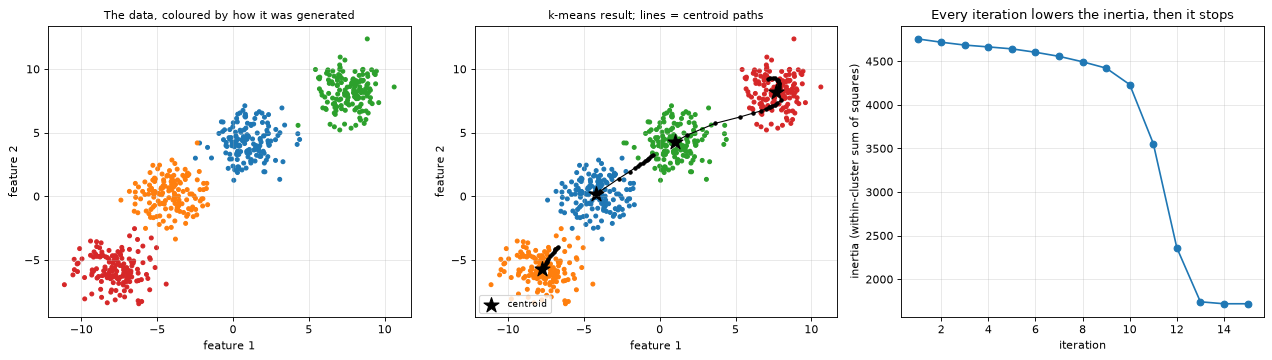

In [2]:
X1, y1 = make_blobs(600, centers=4, cluster_std=1.2, random_state=3)
final = KMeans(4, init="random", n_init=1, random_state=11).fit(X1)   # random starting centroids, run to the end
paths, inertias = [], []
for steps in range(1, final.n_iter_ + 1):                         # re-run 1, 2, ... steps from the same start
    km = KMeans(4, init="random", n_init=1, random_state=11, max_iter=steps).fit(X1)
    paths.append(km.cluster_centers_); inertias.append(km.inertia_)
paths = np.array(paths)
print(f"converged after {final.n_iter_} iterations; inertia (sum of squared distances to own centroid) {final.inertia_:.1f}")
print("inertia after each iteration:", np.round(inertias, 1))
print("points per cluster:", np.bincount(final.labels_))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
plot_clusters(axes[0], X1, y1, "The data, coloured by how it was generated")
plot_clusters(axes[1], X1, final.labels_, "k-means result; lines = centroid paths", final.cluster_centers_)
for k in range(4):
    axes[1].plot(paths[:, k, 0], paths[:, k, 1], "k.-", lw=1)
axes[1].legend(loc="lower left", fontsize=8)
axes[2].plot(range(1, final.n_iter_ + 1), inertias, marker="o")
axes[2].set_xlabel("iteration"); axes[2].set_ylabel("inertia (within-cluster sum of squares)")
axes[2].set_title("Every iteration lowers the inertia, then it stops")
plt.tight_layout(); plt.show()

> **How to read this**
> * Left: the 600 points, coloured by the blob each was generated from. Middle: the k-means result (stars) and the
>   path each centroid took (black dots, one per iteration). The final clusters hold 150 / 150 / 151 / 149 points:
>   essentially the four blobs.
> * Right: the inertia after every iteration, **4756.7 → 1718.5** in 15 iterations. It **never goes up**: the assign
>   step can only shorten each point's distance, and the mean is the point that minimises the squared distances to a
>   group (README §3.3). That is why k-means always stops.
> * The random start put **two** centroids in the top-right blob and left **one** centroid covering the two middle
>   blobs. For 10 iterations the inertia creeps down slowly (4757 → 4233) while one top-right centroid slides down
>   towards the middle; then it drops in three steps once each centroid owns one blob. A different start can stop
>   somewhere worse; that is Lab 2.

<a id="lab-2"></a>

## Lab 2 · Why the starting centroids matter: random vs k-means++

**Goal:** k-means only finds a **local** minimum of the inertia, so where it starts decides where it ends. Compare 100
random starts with 100 **k-means++** starts (README §3.4: each new starting centroid is drawn far from the ones already
chosen) on 10 blobs, and see what scikit-learn's `n_init` does.

random    : median inertia  1551.1, worst 10278.7, runs within 1 % of the best: 3%
k-means++ : median inertia   676.1, worst   966.3, runs within 1 % of the best: 50%

KMeans defaults (k-means++, one run): 644.8;  n_init=10 (best of 10 runs): 644.8


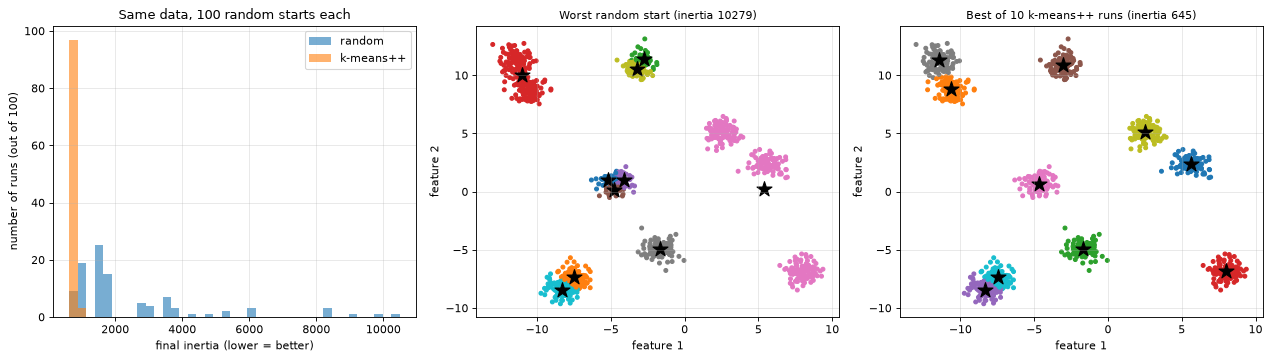

In [3]:
X2, _ = make_blobs(1000, centers=10, cluster_std=0.6, center_box=(-12, 12), random_state=42)
runs = {}
for init in ["random", "k-means++"]:
    runs[init] = np.array([KMeans(10, init=init, n_init=1, random_state=s).fit(X2).inertia_ for s in range(100)])
best = min(r.min() for r in runs.values())
for init, inertia in runs.items():
    print(f"{init:10s}: median inertia {np.median(inertia):7.1f}, worst {inertia.max():7.1f}, "
          f"runs within 1 % of the best: {np.mean(inertia <= best * 1.01):.0%}")
default = KMeans(10, random_state=0).fit(X2)                       # k-means++ and n_init="auto" (1 run for k-means++)
ten_runs = KMeans(10, n_init=10, random_state=0).fit(X2)
print(f"\nKMeans defaults (k-means++, one run): {default.inertia_:.1f};  n_init=10 (best of 10 runs): {ten_runs.inertia_:.1f}")
worst_seed = int(np.argmax(runs["random"]))
worst = KMeans(10, init="random", n_init=1, random_state=worst_seed).fit(X2)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
bins = np.linspace(best * 0.98, max(r.max() for r in runs.values()) * 1.02, 40)
for init, inertia in runs.items():
    axes[0].hist(inertia, bins=bins, alpha=0.6, label=init)
axes[0].set_xlabel("final inertia (lower = better)"); axes[0].set_ylabel("number of runs (out of 100)")
axes[0].set_title("Same data, 100 random starts each"); axes[0].legend()
plot_clusters(axes[1], X2, worst.labels_, f"Worst random start (inertia {worst.inertia_:.0f})", worst.cluster_centers_)
plot_clusters(axes[2], X2, ten_runs.labels_, f"Best of 10 k-means++ runs (inertia {ten_runs.inertia_:.0f})",
              ten_runs.cluster_centers_)
plt.tight_layout(); plt.show()

> **How to read this**
> * **Random starts** (pick 10 data points at random): median inertia **1551**, worst **10279**, and only **3 %** of
>   runs end within 1 % of the best answer. The middle plot is the worst run: some blobs share a centroid while other
>   centroids split one blob.
> * **k-means++ starts:** median **676**, worst **966**, and **50 %** of runs reach the best. Spreading the starting
>   centroids out avoids most bad local minima.
> * scikit-learn's defaults (k-means++, one run) already reach **644.8** here, the same as the best of 10 runs. Setting
>   `n_init` higher simply keeps the run with the lowest inertia: cheap insurance on harder data.

<a id="lab-3"></a>

## Lab 3 · Choosing k: the elbow and the silhouette

**Goal:** k-means needs the number of clusters k up front. Two common ways to pick it (README §3.5):

* **Elbow:** plot the inertia against k and take the k where the curve bends. The bend is found here by the
  "kneedle" idea: the point farthest from the straight line joining the two ends of the curve.
* **Silhouette:** for each point, compare how close it is to its own cluster with how close it is to the nearest other
  cluster; average over all points; take the k with the highest average.

Three datasets: four clear blobs, four blobs arranged as **two pairs** (the example from the original notes), and
uniform noise with no clusters at all.

<details>
<summary><b>The silhouette, in formulas (click to expand)</b></summary>

For point $i$ in cluster $C$:

* $a(i)$ = average distance from $i$ to the other points of its own cluster (how tight its home is);
* $b(i)$ = the smallest, over the other clusters, of the average distance from $i$ to that cluster's points (how far
  the nearest neighbouring cluster is);

$$s(i) = \frac{b(i) - a(i)}{\max\big(a(i),\, b(i)\big)} \in [-1, 1]$$

$s(i)$ near 1: well inside its cluster, far from the next. Near 0: on the border. Negative: closer to another cluster
than to its own. The **mean silhouette** averages $s(i)$ over all points. It isn't defined for $k = 1$ (no other
cluster), so it can never say "there are no clusters". The from-scratch notebook computes it by hand.

</details>

4 clear blobs                elbow (chord) k = 4, best silhouette k = 4 (0.77); silhouette at k=2..5: [0.5  0.59 0.77 0.66]
2 pairs of close blobs       elbow (chord) k = 2, best silhouette k = 2 (0.88); silhouette at k=2..5: [0.88 0.74 0.58 0.52]


uniform noise (no clusters)  elbow (chord) k = 4, best silhouette k = 4 (0.41); silhouette at k=2..5: [0.37 0.38 0.41 0.39]


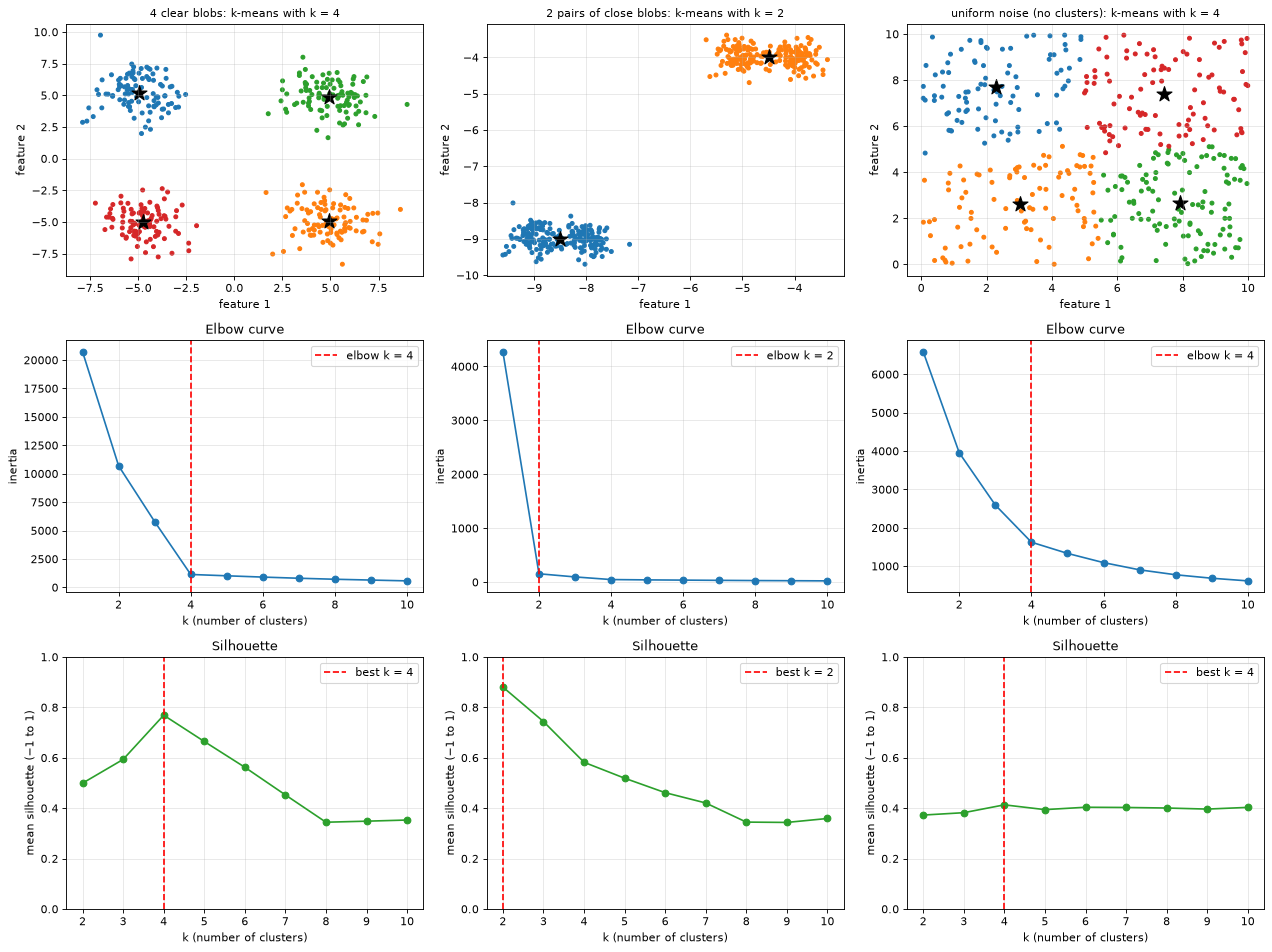

In [4]:
def knee_by_chord(ks, values):
    """The k whose point lies farthest from the straight line joining the first and last points of the curve
    (the 'kneedle' idea): where the curve bends most."""
    ks, values = np.asarray(ks, float), np.asarray(values, float)
    x = (ks - ks[0]) / (ks[-1] - ks[0]); v = (values - values.min()) / (values.max() - values.min())
    chord = v[0] + (v[-1] - v[0]) * x                                  # the straight line between the end points
    return int(ks[np.argmax(np.abs(chord - v))])


rng = np.random.default_rng(SEED)
k_sets = {
    "4 clear blobs": make_blobs(400, centers=[[-5, -5], [5, -5], [-5, 5], [5, 5]], cluster_std=1.2, random_state=1)[0],
    "2 pairs of close blobs": make_blobs(400, cluster_std=0.25, centers=[[-4, -4], [-5, -4], [-9, -9], [-8, -9]],
                                         random_state=1)[0],
    "uniform noise (no clusters)": rng.uniform(0, 10, size=(400, 2)),
}
ks = range(1, 11)
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for col, (name, X) in enumerate(k_sets.items()):
    inertia = [KMeans(k, n_init=10, random_state=SEED).fit(X).inertia_ for k in ks]
    sil = [silhouette_score(X, KMeans(k, n_init=10, random_state=SEED).fit_predict(X)) for k in ks[1:]]
    k_elbow, k_sil = knee_by_chord(ks, inertia), ks[1:][int(np.argmax(sil))]
    print(f"{name:28s} elbow (chord) k = {k_elbow}, best silhouette k = {k_sil} ({max(sil):.2f}); "
          f"silhouette at k=2..5: {np.round(sil[:4], 2)}")
    km = KMeans(k_sil, n_init=10, random_state=SEED).fit(X)
    plot_clusters(axes[0, col], X, km.labels_, f"{name}: k-means with k = {k_sil}", km.cluster_centers_)
    axes[1, col].plot(ks, inertia, marker="o"); axes[1, col].axvline(k_elbow, color="red", ls="--", label=f"elbow k = {k_elbow}")
    axes[1, col].set_xlabel("k (number of clusters)"); axes[1, col].set_ylabel("inertia"); axes[1, col].legend()
    axes[1, col].set_title("Elbow curve")
    axes[2, col].plot(ks[1:], sil, marker="o", color="tab:green")
    axes[2, col].axvline(k_sil, color="red", ls="--", label=f"best k = {k_sil}")
    axes[2, col].set_xlabel("k (number of clusters)"); axes[2, col].set_ylabel("mean silhouette (−1 to 1)")
    axes[2, col].set_ylim(0, 1); axes[2, col].legend(); axes[2, col].set_title("Silhouette")
plt.tight_layout(); plt.show()

> **How to read this**
> * **4 clear blobs:** both methods say **k = 4** (silhouette **0.77**, clearly above k = 3's 0.59 and k = 5's 0.66).
>   When clusters are well separated, the methods agree with the truth.
> * **2 pairs of close blobs:** both say **k = 2** (silhouette **0.88**; k = 4 gets only 0.58), although the data was
>   generated from 4 centres. Both answers are defensible: at a coarse scale there are 2 groups, at a fine scale 4.
>   Scores that compare k values pick the *coarsest* clear structure; a dendrogram (Lab 5) shows both levels.
> * **Uniform noise:** k-means happily cuts it into k = 4 pieces and both methods "choose" 4, but the best silhouette
>   is only **0.41**, against 0.77 and 0.88 for real clusters. k-means always returns clusters; a low silhouette at
>   every k is the warning sign that there may be none.
> * In practice: look at several k, prefer methods that agree, and judge whether the clusters mean something.

<a id="lab-4"></a>

## Lab 4 · Where k-means fails

**Goal:** k-means assigns every point to its **nearest centroid**, so it draws straight borders halfway between
centroids and works best for round clusters of similar size and spread (README §3.6). Test it on the six shapes from
scikit-learn's comparison gallery, with the **true** number of clusters given, plus a dataset with three far outliers.

k-means with the true number of clusters; ARI = agreement with the true groups (1 = perfect, 0 = chance)
  round blobs      ARI 1.00
  stretched blobs  ARI 0.56
  unequal spreads  ARI 0.79
  unequal sizes    ARI 0.88
  moons            ARI 0.25
  circles          ARI -0.00
  3 blobs + 3 far outliers, k = 3: cluster sizes [200   3 100]


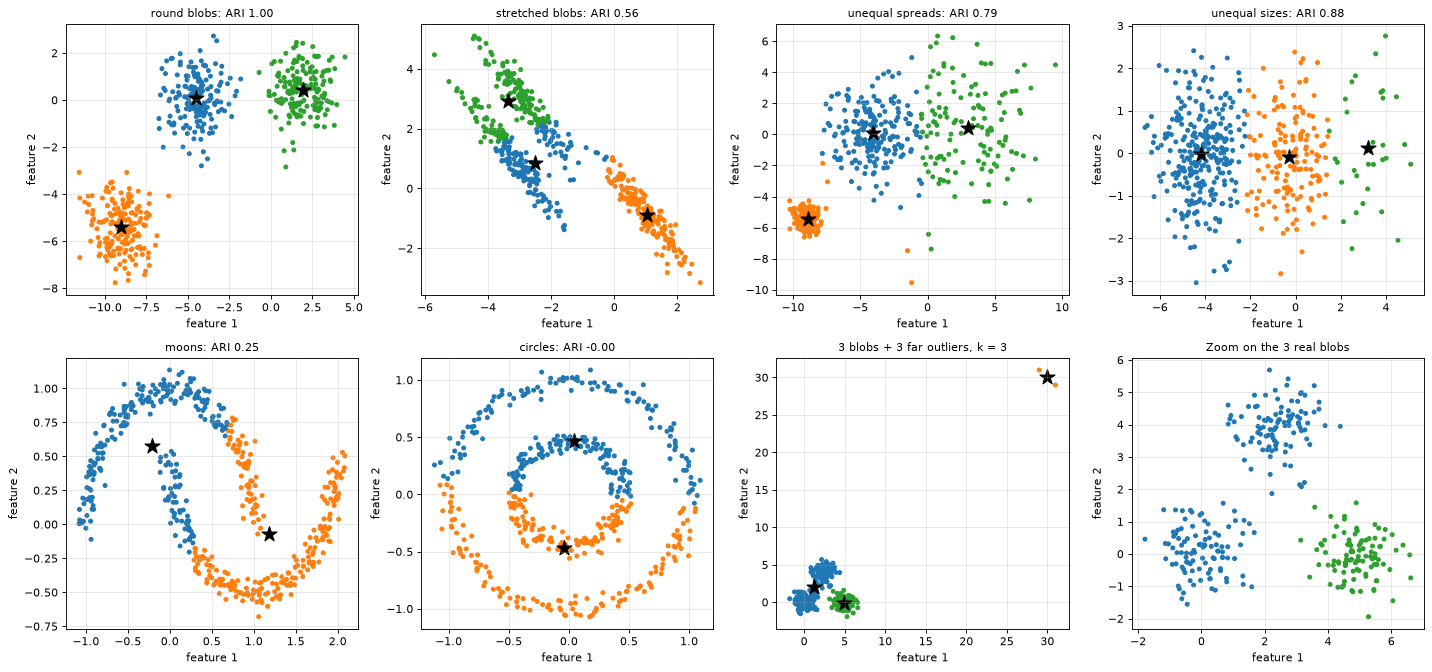

In [5]:
X_out, y_out = make_blobs(300, centers=[[0, 0], [5, 0], [2.5, 4]], cluster_std=0.7, random_state=SEED)
X_out = np.vstack([X_out, [[30, 30], [31, 29], [29, 31]]])            # three far-away outliers
y_out = np.append(y_out, [3, 3, 3])

fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
print("k-means with the true number of clusters; ARI = agreement with the true groups (1 = perfect, 0 = chance)")
for ax, (name, (X, y, k)) in zip(axes.flat, shapes.items()):
    km = KMeans(k, n_init=10, random_state=SEED).fit(X)
    ari = adjusted_rand_score(y, km.labels_)
    print(f"  {name:16s} ARI {ari:.2f}")
    plot_clusters(ax, X, km.labels_, f"{name}: ARI {ari:.2f}", km.cluster_centers_)
km_out = KMeans(3, n_init=10, random_state=SEED).fit(X_out)
print(f"  3 blobs + 3 far outliers, k = 3: cluster sizes {np.bincount(km_out.labels_)}")
plot_clusters(axes[1, 2], X_out, km_out.labels_, "3 blobs + 3 far outliers, k = 3", km_out.cluster_centers_)
plot_clusters(axes[1, 3], X_out[:300], km_out.labels_[:300], "Zoom on the 3 real blobs")
plt.tight_layout(); plt.show()

> **How to read this**
> * **Round blobs: ARI 1.00.** This is the shape k-means assumes.
> * **Stretched blobs: 0.56.** The same blobs, sheared. A nearest-centroid border is a straight line halfway between two
>   centroids, so long, tilted clusters get cut across.
> * **Unequal spreads: 0.79** and **unequal sizes: 0.88.** The border sits halfway between centroids regardless of how
>   wide or big each cluster is, so the large or wide cluster loses its edge points to its neighbour.
> * **Moons: 0.25, circles: −0.00.** Non-convex shapes can't be separated by straight borders at all: k-means cuts the
>   circles in half, top and bottom.
> * **Outliers:** with k = 3 the cluster sizes are **200 / 3 / 100**. The three far points got a cluster to themselves
>   (one centroid sitting on them is the cheapest way to cover their huge squared distances), so two real blobs had to
>   share one centroid (bottom right). Every point is assigned somewhere; k-means has no notion of noise.
> * Parts B and C use methods that don't assume round clusters.

---

<a id="part-b"></a>

# Part B — Hierarchical clustering

<a id="lab-5"></a>

## Lab 5 · Reading and cutting a dendrogram

**Goal:** agglomerative clustering (README §4) starts with every point as its own cluster and repeatedly **merges the
two closest clusters** until one is left. The result is a tree, the **dendrogram**, and any number of clusters can be
read off by cutting it. Here: 12 points (three groups and a loner), **average linkage** (cluster distance = average of
all point-to-point distances between the two clusters).

first 5 merges (cluster ids >= 12 are clusters made by earlier merges):
   i     j   distance  size
   1     3     0.361     2
   7    10     0.424     2
   4     6     0.447     2
   2    12     0.505     3
   9    13     0.539     3
last 3 merges (the big ones):
  11    18     2.177     4
  19    20     4.825     8
  17    21     6.360    12

cut at height 3.0: 3 clusters [1 1 1 1 3 3 3 2 2 2 2 3]
ask for 3 clusters  : [1 1 1 1 3 3 3 2 2 2 2 3]
scikit-learn, 3 clusters, same linkage: [2 2 2 2 1 1 1 3 3 3 3 1]  -> same partition: True


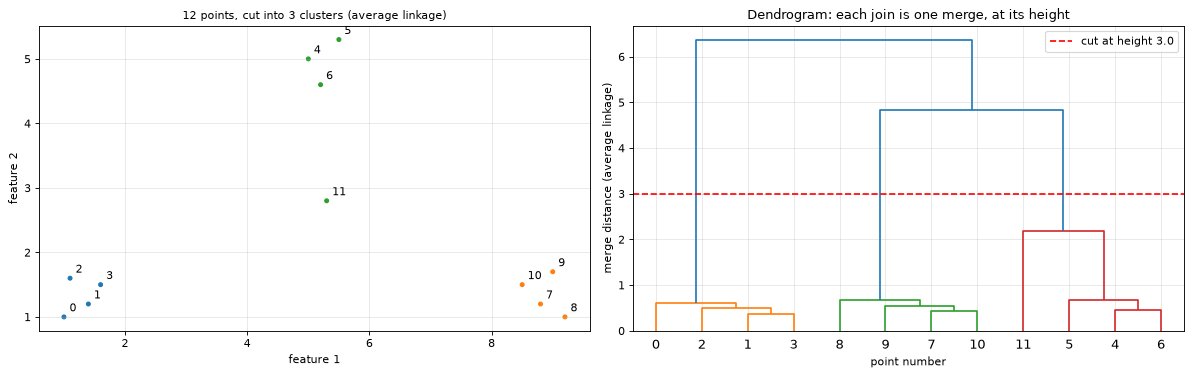

In [6]:
X5 = np.array([[1.0, 1.0], [1.4, 1.2], [1.1, 1.6], [1.6, 1.5],          # group A (points 0-3)
               [5.0, 5.0], [5.5, 5.3], [5.2, 4.6],                      # group B (points 4-6)
               [8.8, 1.2], [9.2, 1.0], [9.0, 1.7], [8.5, 1.5],          # group C (points 7-10)
               [5.3, 2.8]])                                             # a loner between B and C (point 11)
Z = linkage(X5, method="average")                                       # rows: [cluster i, cluster j, distance, size]
print("first 5 merges (cluster ids >= 12 are clusters made by earlier merges):")
print("   i     j   distance  size")
for i, j, d, size in Z[:5]:
    print(f"{int(i):4d}  {int(j):4d}   {d:7.3f}  {int(size):4d}")
print("last 3 merges (the big ones):")
for i, j, d, size in Z[-3:]:
    print(f"{int(i):4d}  {int(j):4d}   {d:7.3f}  {int(size):4d}")

cut_height = 3.0                                                         # <- try another height
by_height = fcluster(Z, t=cut_height, criterion="distance")             # cut the tree at a height
by_count = fcluster(Z, t=3, criterion="maxclust")                       # or ask for a number of clusters
sk = AgglomerativeClustering(n_clusters=3, linkage="average").fit_predict(X5)
print(f"\ncut at height {cut_height}: {len(set(by_height))} clusters {by_height}")
print(f"ask for 3 clusters  : {by_count}")
print(f"scikit-learn, 3 clusters, same linkage: {sk + 1}  -> same partition: {adjusted_rand_score(by_count, sk) == 1.0}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
plot_clusters(axes[0], X5, by_count - 1, "12 points, cut into 3 clusters (average linkage)")
for i, (a, b) in enumerate(X5):
    axes[0].annotate(str(i), (a, b), textcoords="offset points", xytext=(5, 5))
dendrogram(Z, ax=axes[1], color_threshold=cut_height)
axes[1].axhline(cut_height, color="red", ls="--", label=f"cut at height {cut_height}")
axes[1].set_xlabel("point number"); axes[1].set_ylabel("merge distance (average linkage)")
axes[1].set_title("Dendrogram: each join is one merge, at its height"); axes[1].legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * The **linkage matrix** `Z` has one row per merge: the two clusters joined, the distance at which they were joined,
>   and the new cluster's size. Point ids are 0–11; the cluster made by merge number m gets id 12 + m. The first merge
>   joins points 1 and 3 (distance **0.361**), the third joins 4 and 6, and row 4 merges point 2 into cluster 12
>   (the pair 1 + 3).
> * In the dendrogram each ∩ is one merge, drawn at its distance. Short joins at the bottom are the tight groups; the
>   loner (point 11) joins group B late, at **2.177**; the last two merges happen at **4.825** and **6.360**.
> * **Cutting** at height 3.0 (red line) keeps every merge below it: **3 clusters**, `[1 1 1 1 3 3 3 2 2 2 2 3]`.
>   Asking for 3 clusters gives the same answer. scikit-learn's `AgglomerativeClustering` finds the same partition;
>   only the cluster numbers differ.
> * A big vertical gap between consecutive merge heights (here 2.177 → 4.825) is the natural place to cut.

<a id="lab-6"></a>

## Lab 6 · What the linkage changes

**Goal:** the **linkage** is the rule for the distance between two *clusters*, and it decides the shapes the method can
find (README §4.2). Compare the four common ones on moons, unequal spreads, and two blobs joined by a thin bridge of
points, then check how faithfully each tree preserves the real distances on iris.

<details>
<summary><b>The four linkages, in formulas (click to expand)</b></summary>

For clusters $A$ and $B$ with sizes $|A|, |B|$ and point distances $d(a, b)$:

| Linkage | Distance between clusters | Tends to |
|---|---|---|
| **single** | $\min_{a \in A, b \in B} d(a, b)$ (closest pair) | follow chains: finds any shape, but one bridge of points merges two clusters |
| **complete** | $\max_{a, b} d(a, b)$ (farthest pair) | compact clusters of similar diameter |
| **average** | $\frac{1}{\lvert A\rvert \lvert B\rvert} \sum_{a, b} d(a, b)$ | in between |
| **ward** | the increase in total within-cluster sum of squares caused by merging $A$ and $B$: $\frac{\lvert A\rvert \lvert B\rvert}{\lvert A\rvert + \lvert B\rvert} \lVert \mu_A - \mu_B \rVert^2$ | round clusters of similar size, like k-means |

After every merge the distances from the new cluster to all others are updated with one formula (Lance–Williams), so
the point distances never have to be recomputed; the from-scratch notebook implements it.

The **cophenetic distance** between two points is the height at which they first end up in the same cluster. The
**cophenetic correlation** is the correlation between those heights and the real distances: 1 = the tree is a perfect
summary of the distances.

</details>

ARI (1 = matches the true groups)          single  complete   average      ward
  moons                                     1.00      0.45      0.45      0.56
  unequal spreads                           0.00      0.59      0.57      0.61
  2 blobs + a thin bridge                  -0.00      0.99      0.95      0.95

iris (standardised): cophenetic correlation = how faithfully the tree's merge heights keep the real distances
  single   cophenetic correlation 0.830   ARI with 3 clusters 0.56
  complete cophenetic correlation 0.751   ARI with 3 clusters 0.57
  average  cophenetic correlation 0.854   ARI with 3 clusters 0.56
  ward     cophenetic correlation 0.823   ARI with 3 clusters 0.62


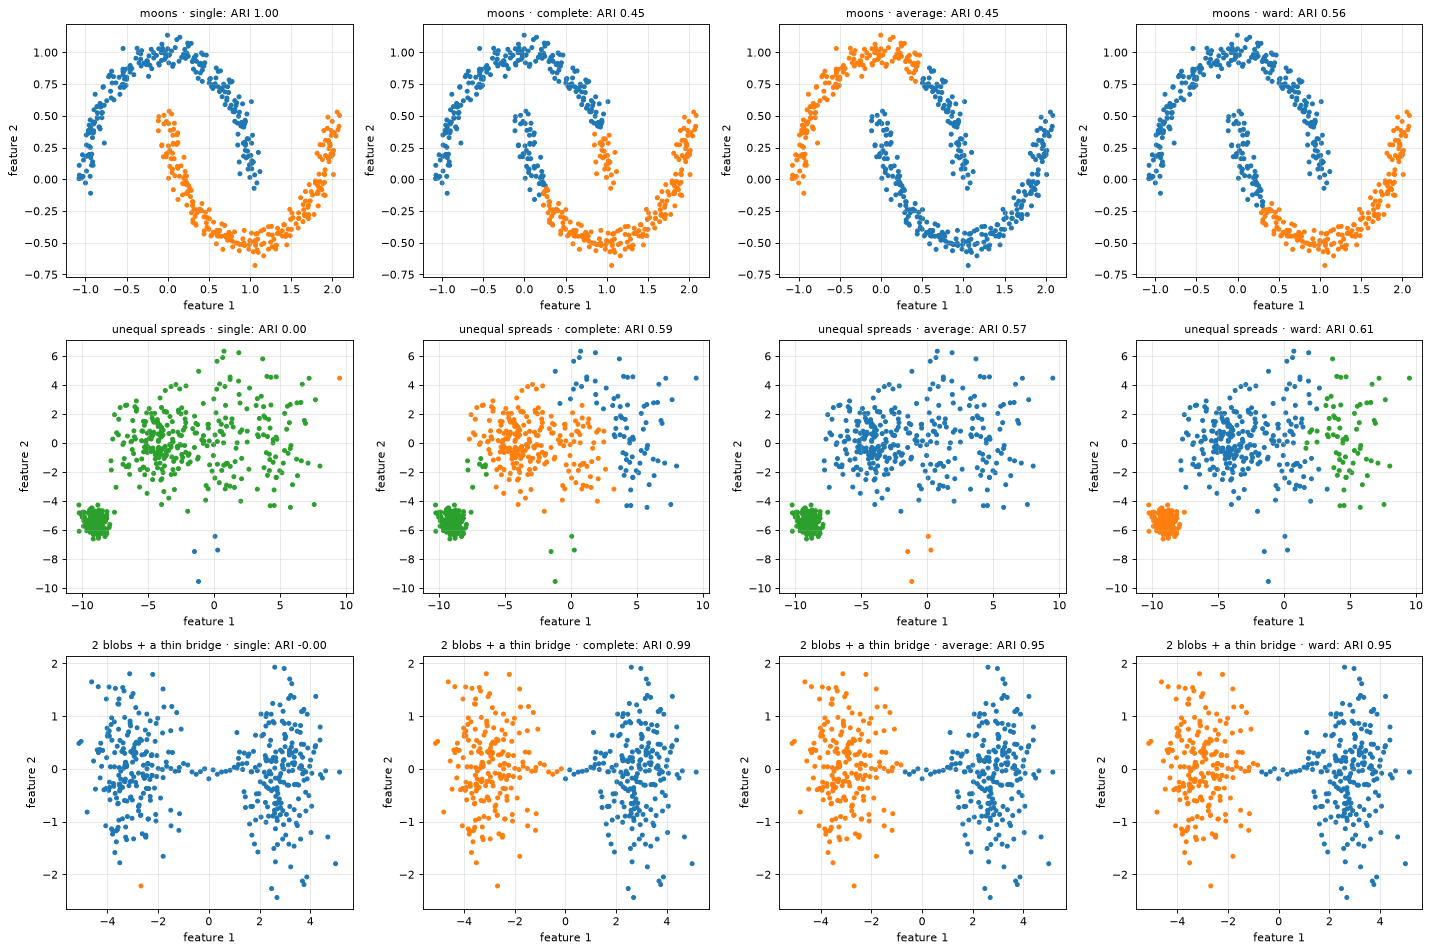

In [7]:
X_bridge, y_bridge = make_blobs(400, centers=[[-3, 0], [3, 0]], cluster_std=0.8, random_state=SEED)
bridge = np.column_stack([np.linspace(-2, 2, 25), np.random.default_rng(SEED).normal(0, 0.08, 25)])
X_bridge = np.vstack([X_bridge, bridge]); y_bridge = np.append(y_bridge, (bridge[:, 0] > 0).astype(int))
link_sets = {"moons": shapes["moons"][:2], "unequal spreads": shapes["unequal spreads"][:2],
             "2 blobs + a thin bridge": (X_bridge, y_bridge)}
linkages = ["single", "complete", "average", "ward"]

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
print("ARI (1 = matches the true groups)        " + "  ".join(f"{m:>8s}" for m in linkages))
for row, (name, (X, y)) in enumerate(link_sets.items()):
    k = len(np.unique(y)); aris = []
    for col, method in enumerate(linkages):
        labels = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X)
        aris.append(adjusted_rand_score(y, labels))
        plot_clusters(axes[row, col], X, labels, f"{name} · {method}: ARI {aris[-1]:.2f}")
    print(f"  {name:38s}" + "  ".join(f"{a:8.2f}" for a in aris))

iris_X = StandardScaler().fit_transform(load_iris().data)
print("\niris (standardised): cophenetic correlation = how faithfully the tree's merge heights keep the real distances")
for method in linkages:
    Zi = linkage(iris_X, method=method)
    c, _ = cophenet(Zi, pdist(iris_X))
    ari = adjusted_rand_score(load_iris().target, fcluster(Zi, 3, criterion="maxclust"))
    print(f"  {method:8s} cophenetic correlation {c:.3f}   ARI with 3 clusters {ari:.2f}")
plt.tight_layout(); plt.show()

> **How to read this**
> * **Moons:** only **single** linkage gets them (ARI **1.00**); complete 0.45, average 0.45, ward 0.56. Following the
>   chain of nearest neighbours traces any shape.
> * **Unequal spreads:** single linkage scores **0.00**: one giant cluster of 495 points, and the other two "clusters"
>   are 4 and 1 stray points from the wide cluster's edge. Every gap inside the data is bridged by some chain of near
>   neighbours. Ward does best (0.61).
> * **Two blobs + a thin bridge:** single linkage again **0.00**: the bridge chains the blobs into one cluster of 424
>   points plus 1 leftover point. Complete **0.99**, average and ward 0.95.
> * **Iris:** average linkage keeps the real distances best (cophenetic correlation **0.854**), but ward gives the best
>   3-cluster split (ARI **0.62**). A tree that summarises distances well is not necessarily the best cut.
> * So: single linkage for odd shapes with clean gaps; ward (or complete) for compact clusters and noisy data.

---

<a id="part-c"></a>

# Part C — Density-based clustering

<a id="lab-7"></a>

## Lab 7 · DBSCAN: core, border and noise points, and choosing eps

**Goal:** DBSCAN (README §5) calls a point a **core point** if at least `min_samples` points (itself included) lie
within distance `eps`. Core points closer than `eps` to each other are chained into one cluster; non-core points within
`eps` of a core point join as **border points**; everything else is **noise**. Clusters can have any shape, and the
number of clusters is not given. Data: two moons plus 20 stray points.

**Choosing eps:** sort every point's distance to its `min_samples`-th nearest neighbour (the **k-distance plot**).
Points inside clusters have small values; noise points have large ones; the bend in between is a good `eps`. The bend is
found here with the same chord rule as Lab 3.

eps chosen at the knee of the k-distance curve: 0.164
core points 403, border points 4, noise points 13; clusters found: 2
ARI on the 400 moon points: DBSCAN 1.00, k-means (k = 2) 0.26
of the 20 stray points, DBSCAN called 13 noise


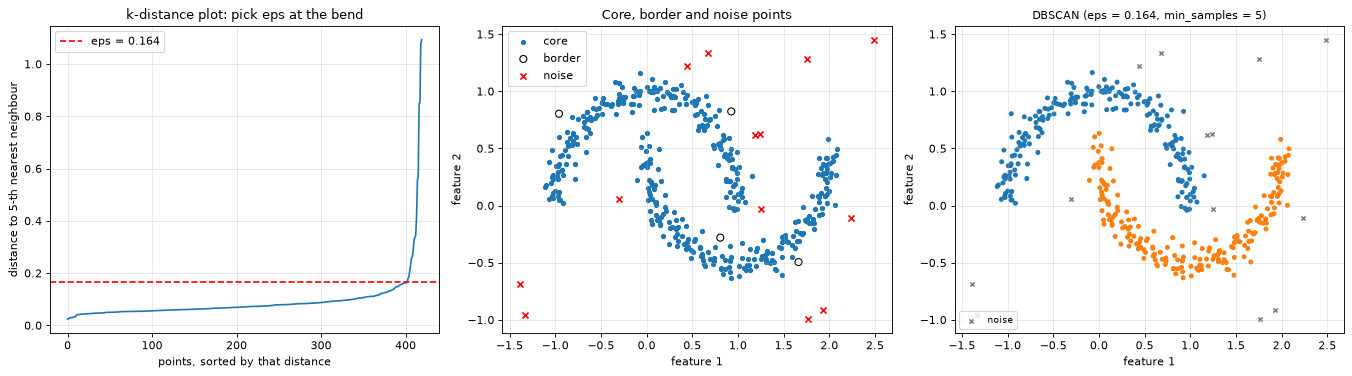

In [8]:
X7, y7 = make_moons(400, noise=0.07, random_state=SEED)
X7 = np.vstack([X7, np.random.default_rng(SEED).uniform([-1.5, -1], [2.5, 1.5], size=(20, 2))])   # 20 stray points
y7 = np.append(y7, [-1] * 20)
MIN_SAMPLES = 5                                                          # <- try 3 or 10

# k-distance plot: distance from each point to its MIN_SAMPLES-th nearest neighbour (counting itself), sorted
k_dist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X7).kneighbors(X7)[0][:, -1])
eps = float(k_dist[knee_by_chord(np.arange(len(k_dist)), k_dist)])      # where the sorted curve bends upward
db = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit(X7)
core = np.zeros(len(X7), bool); core[db.core_sample_indices_] = True
border = (db.labels_ != -1) & ~core
print(f"eps chosen at the knee of the k-distance curve: {eps:.3f}")
print(f"core points {core.sum()}, border points {border.sum()}, noise points {(db.labels_ == -1).sum()}; "
      f"clusters found: {db.labels_.max() + 1}")
moons_only = y7 != -1
print(f"ARI on the 400 moon points: DBSCAN {adjusted_rand_score(y7[moons_only], db.labels_[moons_only]):.2f}, "
      f"k-means (k = 2) {adjusted_rand_score(y7[moons_only], KMeans(2, n_init=10, random_state=SEED).fit_predict(X7)[moons_only]):.2f}")
print(f"of the 20 stray points, DBSCAN called {(db.labels_[~moons_only] == -1).sum()} noise")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].plot(k_dist); axes[0].axhline(eps, color="red", ls="--", label=f"eps = {eps:.3f}")
axes[0].set_xlabel("points, sorted by that distance"); axes[0].set_ylabel(f"distance to {MIN_SAMPLES}-th nearest neighbour")
axes[0].set_title("k-distance plot: pick eps at the bend"); axes[0].legend()
for mask, style, label in [(core, dict(s=14), "core"), (border, dict(s=40, facecolors="none", edgecolors="k"), "border"),
                           (db.labels_ == -1, dict(s=30, marker="x", c="red"), "noise")]:
    axes[1].scatter(X7[mask, 0], X7[mask, 1], label=label, **style)
axes[1].set_xlabel("feature 1"); axes[1].set_ylabel("feature 2"); axes[1].set_title("Core, border and noise points")
axes[1].legend()
plot_clusters(axes[2], X7, db.labels_, f"DBSCAN (eps = {eps:.3f}, min_samples = {MIN_SAMPLES})")
axes[2].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

> **How to read this**
> * Left: the sorted k-distances are flat (inside the moons) and then shoot up (the strays). The bend gives
>   **eps = 0.164**.
> * Middle: **403 core** points (the bulk), **4 border** points (circles at the edges) and **13 noise** points
>   (red ×).
> * Right: DBSCAN finds **2 clusters** and matches the two moons exactly (**ARI 1.00** on the moon points), where k-means
>   gets 0.26. Of the 20 stray points, 13 are called noise; the other 7 happened to land within `eps` of a moon and
>   joined it.
> * `min_samples` is the smoothing knob: larger values need denser regions to start a cluster and label more points as
>   noise. A common starting point is 2 × the number of features; here 5 for 2 features.

<a id="lab-8"></a>

## Lab 8 · DBSCAN's weak spot: one eps for every cluster

**Goal:** see how sensitive DBSCAN is to `eps` and `min_samples`, and what happens when clusters have different
densities (README §5.4). Left: the moons over a grid of settings. Right: two dense blobs close together and one sparse
blob far away, at three values of `eps`.

moons: ARI for each (min_samples, eps); clusters found in brackets
  min_samples  3: 0.02 (37)  0.61 (5)  1.00 (2)  1.00 (2)  0.00 (1)  0.00 (1)
  min_samples  5: 0.01 (21)  0.60 (5)  1.00 (2)  1.00 (2)  0.00 (1)  0.00 (1)
  min_samples 10: 0.00 (0)  0.07 (21)  0.98 (2)  1.00 (2)  0.00 (1)  0.00 (1)
  min_samples 20: 0.00 (0)  0.00 (0)  0.02 (4)  0.97 (2)  0.00 (1)  0.00 (1)

three blobs, two dense and close, one sparse and far:


  eps 0.25: 2 clusters; dense blobs merged: no ; sparse blob called noise: 100%
  eps 0.60: 3 clusters; dense blobs merged: yes; sparse blob called noise: 70%
  eps 1.20: 2 clusters; dense blobs merged: yes; sparse blob called noise: 10%


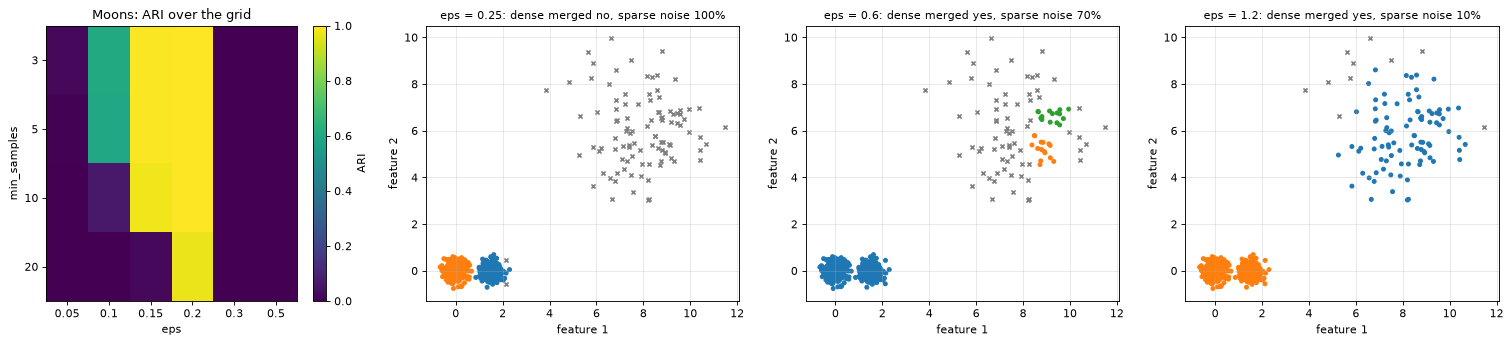

In [9]:
eps_grid = [0.05, 0.1, 0.15, 0.2, 0.3, 0.5]
ms_grid = [3, 5, 10, 20]
grid = np.array([[adjusted_rand_score(y7[moons_only], DBSCAN(eps=e, min_samples=m).fit_predict(X7)[moons_only])
                  for e in eps_grid] for m in ms_grid])
n_found = np.array([[DBSCAN(eps=e, min_samples=m).fit_predict(X7).max() + 1 for e in eps_grid] for m in ms_grid])

X_dens, y_dens = make_blobs([300, 300, 100], centers=[[0, 0], [1.5, 0], [8, 6]], cluster_std=[0.25, 0.25, 1.5],
                            random_state=SEED)                   # two dense blobs close together, one sparse blob far away


def density_report(labels):
    """What happened to the three true blobs: did the two dense ones (0, 1) end up in one cluster, and how much of
    the sparse one (2) was called noise?"""
    dense_a, dense_b = [np.bincount(labels[y_dens == g] + 1).argmax() - 1 for g in (0, 1)]   # majority label
    merged = dense_a == dense_b and dense_a != -1
    return labels.max() + 1, merged, np.mean(labels[y_dens == 2] == -1)


print("moons: ARI for each (min_samples, eps); clusters found in brackets")
for m, row, found in zip(ms_grid, grid, n_found):
    print(f"  min_samples {m:2d}: " + "  ".join(f"{a:4.2f} ({f})" for a, f in zip(row, found)))
print("\nthree blobs, two dense and close, one sparse and far:")
fig, axes = plt.subplots(1, 4, figsize=(19, 4.4))
image = axes[0].imshow(grid, cmap="viridis", vmin=0, vmax=1, aspect="auto")
axes[0].set_xticks(range(len(eps_grid)), eps_grid); axes[0].set_yticks(range(len(ms_grid)), ms_grid)
axes[0].set_xlabel("eps"); axes[0].set_ylabel("min_samples"); axes[0].set_title("Moons: ARI over the grid")
axes[0].grid(False); fig.colorbar(image, ax=axes[0], label="ARI")
for ax, e in zip(axes[1:], [0.25, 0.6, 1.2]):
    labels = DBSCAN(eps=e, min_samples=10).fit_predict(X_dens)
    found, merged, sparse_noise = density_report(labels)
    print(f"  eps {e:4.2f}: {found} clusters; dense blobs merged: {'yes' if merged else 'no '}; "
          f"sparse blob called noise: {sparse_noise:.0%}")
    plot_clusters(ax, X_dens, labels, f"eps = {e}: dense merged {'yes' if merged else 'no'}, sparse noise {sparse_noise:.0%}")
plt.tight_layout(); plt.show()

> **How to read this**
> * **Moons grid:** the right answer (ARI ≈ 1, 2 clusters) only appears for **eps 0.15–0.2**. Smaller eps shatters the
>   moons into many small clusters (37 at eps 0.05, min_samples 3) or calls everything noise (0 clusters); larger eps
>   merges both moons into one cluster.
> * **Mixed densities**, `min_samples` = 10:
>   * **eps 0.25** separates the two dense blobs but calls **100 %** of the sparse blob noise;
>   * **eps 0.6** has already merged the dense blobs and still calls **70 %** of the sparse blob noise (the rest
>     becomes two fragments);
>   * **eps 1.2** finally finds the sparse blob (**10 %** noise) but has merged the dense blobs.
> * No single `eps` gets all three. The dense blobs need a small radius and the sparse one a large radius: that is
>   exactly the problem OPTICS and HDBSCAN solve (Lab 9).

<a id="lab-9"></a>

## Lab 9 · OPTICS and HDBSCAN: clusters of different density

**Goal:** OPTICS (README §6) doesn't fix `eps`. It visits the points in an order that always moves to the nearest
not-yet-visited dense region, and records each point's **reachability distance** (roughly, how far it is from the dense
region it was reached from). Plotting reachability in that order gives the **reachability plot**: valleys are clusters,
peaks are the gaps between them. Clusters can then be extracted with the **xi** method (steep drops and rises) or by a
DBSCAN-style horizontal cut at any `eps`, with no refitting. HDBSCAN (README §6.4) builds on the same idea and returns
flat clusters automatically. Same mixed-density data as Lab 8.

<details>
<summary><b>Core distance and reachability distance (click to expand)</b></summary>

* **Core distance** of point $p$: the distance to its `min_samples`-th nearest neighbour (counting $p$ itself). It is
  the smallest `eps` that would make $p$ a core point.
* **Reachability distance** of $o$ from $p$: $\max\big(\text{core distance}(p),\ d(p, o)\big)$. A point right next to
  $p$ can't look closer than $p$'s core distance, which smooths out random gaps inside dense regions.
* OPTICS repeatedly takes the unvisited point with the **smallest** reachability so far, records it, and lowers its
  unvisited neighbours' reachability values. Points of one dense region are visited one after another with small
  values (a valley); jumping to the next region needs a large value (a peak).
* Cutting the plot at height $\varepsilon$ gives exactly what DBSCAN with that $\varepsilon$ would give (up to the
  odd border point), which is why one OPTICS run contains every DBSCAN answer.

</details>

OPTICS (xi = 0.1)                3 clusters; dense blobs merged: no ; sparse blob called noise:   0%; noise overall   0%
OPTICS (xi = 0.05)               3 clusters; dense blobs merged: no ; sparse blob called noise:  32%; noise overall  36%
OPTICS cut at eps = 0.25         2 clusters; dense blobs merged: no ; sparse blob called noise: 100%; noise overall  15%
OPTICS cut at eps = 1.2          2 clusters; dense blobs merged: yes; sparse blob called noise:  10%; noise overall   1%
HDBSCAN (min_cluster_size = 20)  3 clusters; dense blobs merged: no ; sparse blob called noise:   0%; noise overall   2%
time on 700 points, DBSCAN : 0.001 s
time on 700 points, OPTICS : 0.173 s
time on 700 points, HDBSCAN: 0.003 s


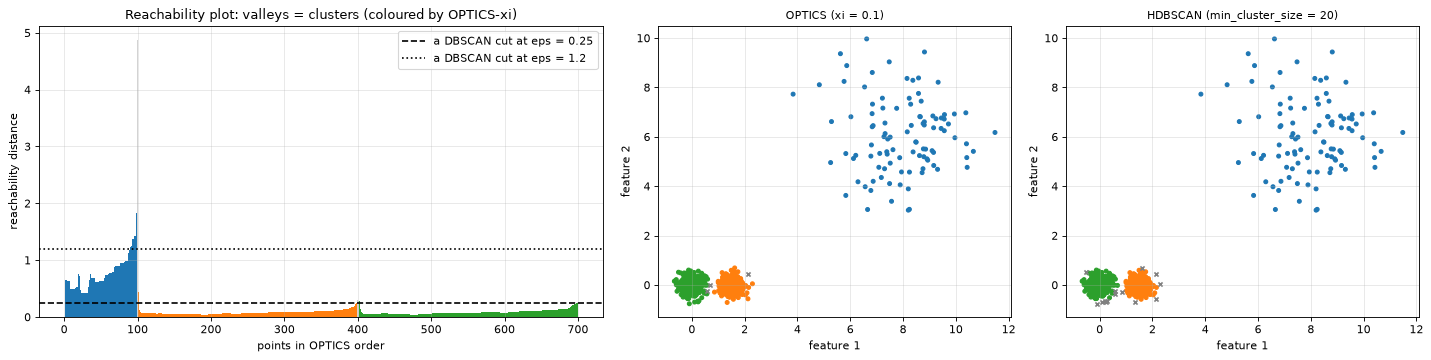

In [10]:
optics = OPTICS(min_samples=10, xi=0.1, min_cluster_size=0.05).fit(X_dens)   # <- try xi = 0.05
reach = optics.reachability_[optics.ordering_]
results = {"OPTICS (xi = 0.1)": optics.labels_,
           "OPTICS (xi = 0.05)": OPTICS(min_samples=10, xi=0.05, min_cluster_size=0.05).fit_predict(X_dens)}
for e in [0.25, 1.2]:
    results[f"OPTICS cut at eps = {e}"] = cluster_optics_dbscan(reachability=optics.reachability_,
                                                                 core_distances=optics.core_distances_,
                                                                 ordering=optics.ordering_, eps=e)
results["HDBSCAN (min_cluster_size = 20)"] = HDBSCAN(min_cluster_size=20, copy=True).fit_predict(X_dens)
for name, labels in results.items():
    found, merged, sparse_noise = density_report(labels)
    print(f"{name:32s} {found} clusters; dense blobs merged: {'yes' if merged else 'no '}; "
          f"sparse blob called noise: {sparse_noise:4.0%}; noise overall {np.mean(labels == -1):4.0%}")
for name, model in [("DBSCAN", DBSCAN(eps=0.25, min_samples=10)), ("OPTICS", OPTICS(min_samples=10)),
                    ("HDBSCAN", HDBSCAN(min_cluster_size=20, copy=True))]:
    start = time.perf_counter(); model.fit(X_dens)
    print(f"time on {len(X_dens)} points, {name:7s}: {time.perf_counter() - start:.3f} s")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={"width_ratios": [1.6, 1, 1]})
colors = ["lightgray" if label == -1 else plt.cm.tab10(label % 10) for label in optics.labels_[optics.ordering_]]
axes[0].bar(range(len(reach)), np.where(np.isinf(reach), np.nan, reach), color=colors, width=1.0)
for e, ls in [(0.25, "--"), (1.2, ":")]:
    axes[0].axhline(e, color="black", ls=ls, label=f"a DBSCAN cut at eps = {e}")
axes[0].set_xlabel("points in OPTICS order"); axes[0].set_ylabel("reachability distance")
axes[0].set_title("Reachability plot: valleys = clusters (coloured by OPTICS-xi)"); axes[0].legend()
plot_clusters(axes[1], X_dens, results["OPTICS (xi = 0.1)"], "OPTICS (xi = 0.1)")
plot_clusters(axes[2], X_dens, results["HDBSCAN (min_cluster_size = 20)"], "HDBSCAN (min_cluster_size = 20)")
plt.tight_layout(); plt.show()

> **How to read this**
> * **Reachability plot** (left): the first 100 points (blue) are the sparse blob, with reachability around 0.5–1.8;
>   then two long, low valleys (about 0.05–0.1) are the dense blobs, separated by a small peak near point 400.
> * **Horizontal cuts reproduce DBSCAN:** cutting at 0.25 gives Lab 8's eps-0.25 answer (dense blobs separate, sparse
>   blob **100 %** noise); cutting at 1.2 gives the eps-1.2 answer (dense blobs merged, **10 %** noise). One OPTICS
>   run contains every DBSCAN result.
> * **xi extraction** finds clusters by valley depth instead of one height, so it gets all three: with **xi = 0.1**,
>   3 clusters, the dense blobs kept apart, **0 %** noise. It has its own knob: **xi = 0.05** also finds 3 clusters but
>   calls 32 % of the sparse blob noise.
> * **HDBSCAN** finds all three (3 clusters, dense blobs apart, **2 %** noise) with one intuitive setting,
>   `min_cluster_size`.
> * **Speed** on these 700 points (printed above; yours will differ): DBSCAN and HDBSCAN take a few milliseconds,
>   OPTICS takes far longer. In scikit-learn OPTICS is the slowest of the three.

---

<a id="part-d"></a>

# Part D — In practice

<a id="lab-10"></a>

## Lab 10 · Scale the features first

**Goal:** every method here measures distances, and a distance adds up the squared differences of all features, so a
feature measured in large numbers dominates (README §2.2). The wine data has 13 chemical measurements of 178 wines
from 3 cultivars, in very different units.

feature spreads (std) range from 0.12 (nonflavanoid_phenols) to 314 (proline)
ARI with the 3 grape cultivars:        raw    standardised
  k-means (k = 3)                    0.37    0.90
  agglomerative, ward                0.37    0.79


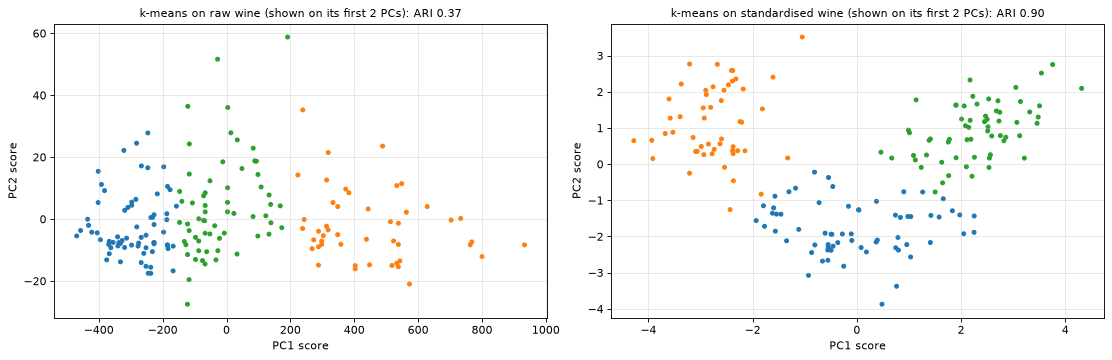

In [11]:
wine = load_wine()
wine_scaled = StandardScaler().fit_transform(wine.data)
print("feature spreads (std) range from", f"{wine.data.std(axis=0).min():.2f} ({wine.feature_names[wine.data.std(axis=0).argmin()]})",
      "to", f"{wine.data.std(axis=0).max():.0f} ({wine.feature_names[wine.data.std(axis=0).argmax()]})")
print("ARI with the 3 grape cultivars:        raw    standardised")
for name, model in [("k-means (k = 3)", KMeans(3, n_init=10, random_state=SEED)),
                    ("agglomerative, ward", AgglomerativeClustering(3, linkage="ward"))]:
    raw = adjusted_rand_score(wine.target, model.fit_predict(wine.data))
    scaled = adjusted_rand_score(wine.target, model.fit_predict(wine_scaled))
    print(f"  {name:22s}            {raw:5.2f}   {scaled:5.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, data, title in [(axes[0], wine.data, "raw"), (axes[1], wine_scaled, "standardised")]:
    two = PCA(2).fit_transform(data)                                    # a 2-D view only, clustering used all 13 columns
    labels = KMeans(3, n_init=10, random_state=SEED).fit_predict(data)
    plot_clusters(ax, two, labels, f"k-means on {title} wine (shown on its first 2 PCs): "
                  f"ARI {adjusted_rand_score(wine.target, labels):.2f}")
    ax.set_xlabel("PC1 score"); ax.set_ylabel("PC2 score")
plt.tight_layout(); plt.show()

> **How to read this**
> * Feature spreads range from **0.12** (nonflavanoid phenols) to **314** (proline). Unscaled, the distance between two
>   wines is essentially their difference in proline.
> * **k-means:** ARI **0.37** on raw data → **0.90** after standardising (each feature: subtract its mean, divide by its
>   standard deviation). **Ward:** 0.37 → 0.79.
> * The plots show both results on the data's first 2 principal components (a 2-D view only; the clustering used all 13
>   columns). Raw: the clusters are slices of proline. Standardised: three clean groups.
> * Standardise unless the units really are comparable (e.g. all pixels, all coordinates in metres). The PCA lab makes
>   the same point for PCA (Lab 10).

<a id="lab-11"></a>

## Lab 11 · Scoring a clustering without true labels

**Goal:** real clustering problems have no true groups, so the scores that need them (ARI, NMI) are unavailable.
**Internal** scores judge the clusters from the data alone (README §7). Compare them on the moons, where DBSCAN is
right and k-means is wrong.

<details>
<summary><b>The five scores (click to expand)</b></summary>

**Need the true labels** (useful for testing a method on data where the answer is known):

* **ARI (adjusted Rand index):** of all pairs of points, how often the clustering and the truth agree on "same group"
  vs "different groups", corrected so that random labels score 0. Max 1.
* **NMI (normalised mutual information):** how much knowing a point's cluster tells you about its true group, scaled
  to 0–1.

**Need only the data:**

* **Silhouette** (Lab 3): tight-and-separated per point, averaged. −1 to 1, higher is better.
* **Davies–Bouldin:** for each cluster, the worst ratio (spread of cluster i + spread of cluster j) / distance between
  their centres; averaged. Lower is better, 0 is best.
* **Calinski–Harabasz:** between-cluster variance / within-cluster variance, adjusted for the number of clusters.
  Higher is better.

All three internal scores are built from centres, averages or distances to the nearest cluster, so they reward
**round, well-separated** clusters.

</details>

                        ARI    NMI | silhouette  Davies-Bouldin  Calinski-Harabasz
                      needs labels | higher=better    lower=better      higher=better
k-means (k = 2)        0.25   0.19 |       0.49            0.78                740
DBSCAN (eps = 0.15)    1.00   0.99 |       0.05            1.13                163


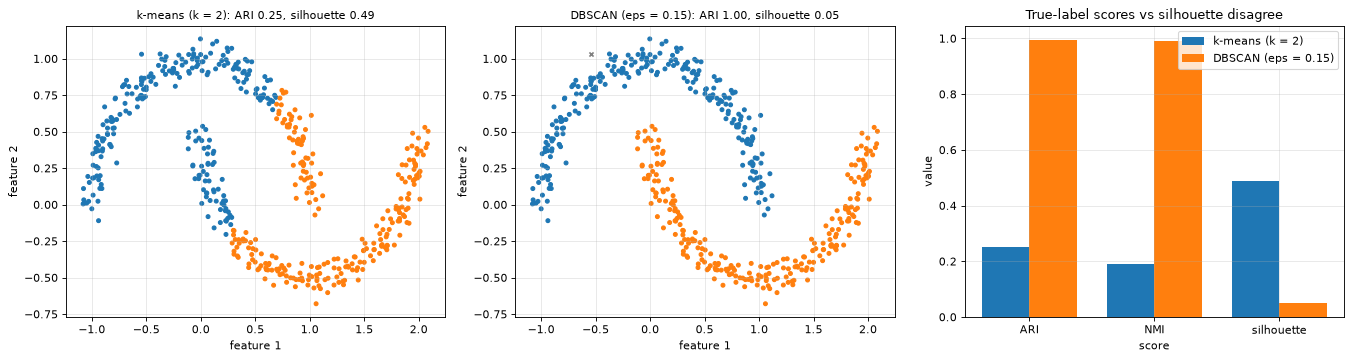

In [12]:
X11, y11 = make_moons(500, noise=0.06, random_state=SEED)
candidates = {"k-means (k = 2)": KMeans(2, n_init=10, random_state=SEED).fit_predict(X11),
              "DBSCAN (eps = 0.15)": DBSCAN(eps=0.15, min_samples=5).fit_predict(X11)}
rows = {}
print(f"{'':20s} {'ARI':>6s} {'NMI':>6s} | {'silhouette':>10s} {'Davies-Bouldin':>15s} {'Calinski-Harabasz':>18s}")
print(f"{'':20s} {'needs labels':>13s} | {'higher=better':>10s} {'lower=better':>15s} {'higher=better':>18s}")
for name, labels in candidates.items():
    rows[name] = [adjusted_rand_score(y11, labels), normalized_mutual_info_score(y11, labels),
                  silhouette_score(X11, labels), davies_bouldin_score(X11, labels), calinski_harabasz_score(X11, labels)]
    print(f"{name:20s} {rows[name][0]:6.2f} {rows[name][1]:6.2f} | {rows[name][2]:10.2f} {rows[name][3]:15.2f} {rows[name][4]:18.0f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (name, labels) in zip(axes, candidates.items()):
    plot_clusters(ax, X11, labels, f"{name}: ARI {rows[name][0]:.2f}, silhouette {rows[name][2]:.2f}")
metric_names = ["ARI", "NMI", "silhouette"]
width = 0.38
for i, (name, values) in enumerate(rows.items()):
    axes[2].bar(np.arange(3) + i * width, values[:3], width, label=name)
axes[2].set_xticks(np.arange(3) + width / 2, metric_names)
axes[2].set_xlabel("score"); axes[2].set_ylabel("value"); axes[2].set_title("True-label scores vs silhouette disagree")
axes[2].legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * The true-label scores agree: DBSCAN is right (**ARI 1.00, NMI 0.99**), k-means is wrong (**0.25, 0.19**).
> * Every internal score prefers the **wrong** answer: silhouette **0.49** for k-means vs **0.05** for DBSCAN;
>   Davies–Bouldin 0.78 vs 1.13 (lower is "better"); Calinski–Harabasz 740 vs 163.
> * Why: two interleaved crescents are not "compact and far apart". Many points on one moon are closer to the other
>   moon's points than to the far end of their own moon, so their silhouette is low or negative.
> * Internal scores are fine for comparing k within one method that makes round clusters (Lab 3). Across methods, or
>   for non-round clusters, they can mislead: look at the clusters and check whether they mean something.

<a id="lab-12"></a>

## Lab 12 · All methods on real data

**Goal:** run the methods side by side on three real datasets that ship with scikit-learn, all standardised (digits
reduced to 20 principal components first, as in the PCA lab's Lab 17). The centroid and hierarchical methods get the
true number of clusters; HDBSCAN and OPTICS decide it themselves. ARI counts noise points as one extra group.


iris (4 columns)  (true clusters: 3)
  method                   ARI  noise  clusters  seconds
  k-means                 0.62     0%         3    0.004
  agglomerative ward      0.62     0%         3    0.000
  agglomerative single    0.56     0%         3    0.000
  HDBSCAN                 0.56     1%         2    0.001
  OPTICS (xi)             0.40    13%         3    0.041

wine (13 columns)  (true clusters: 3)
  method                   ARI  noise  clusters  seconds
  k-means                 0.90     0%         3    0.003
  agglomerative ward      0.79     0%         3    0.000
  agglomerative single   -0.01     0%         3    0.000
  HDBSCAN                 0.26    42%         2    0.001
  OPTICS (xi)             0.00     0%         1    0.049

digits (64 → 20 PCs)  (true clusters: 10)
  method                   ARI  noise  clusters  seconds
  k-means                 0.67     0%        10    0.039
  agglomerative ward      0.78     0%        10    0.021
  agglomerative single   

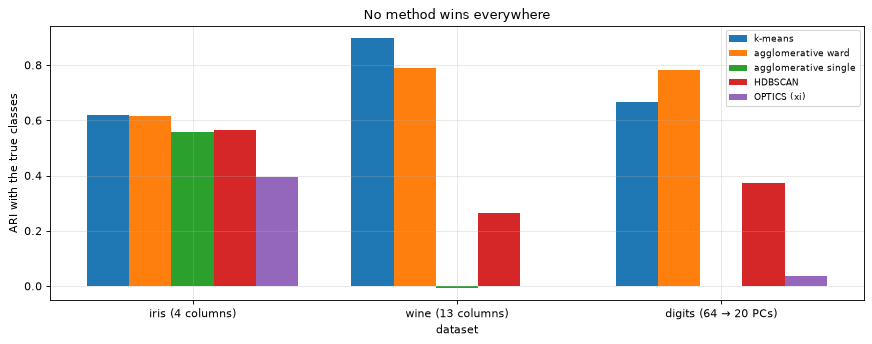

In [13]:
digits = load_digits()
datasets = {"iris (4 columns)": (StandardScaler().fit_transform(load_iris().data), load_iris().target),
            "wine (13 columns)": (wine_scaled, wine.target),
            "digits (64 → 20 PCs)": (PCA(20, random_state=SEED).fit_transform(digits.data), digits.target)}
table = {}
for data_name, (X, y) in datasets.items():
    k = len(np.unique(y))
    models = {"k-means": KMeans(k, n_init=10, random_state=SEED),
              "agglomerative ward": AgglomerativeClustering(k, linkage="ward"),
              "agglomerative single": AgglomerativeClustering(k, linkage="single"),
              "HDBSCAN": HDBSCAN(min_cluster_size=10, copy=True),
              "OPTICS (xi)": OPTICS(min_samples=10)}
    for model_name, model in models.items():
        start = time.perf_counter(); labels = model.fit_predict(X); seconds = time.perf_counter() - start
        table[data_name, model_name] = (adjusted_rand_score(y, labels), np.mean(labels == -1), labels.max() + 1, seconds)
for data_name in datasets:
    print(f"\n{data_name}  (true clusters: {len(np.unique(datasets[data_name][1]))})")
    print(f"  {'method':22s} {'ARI':>5s} {'noise':>6s} {'clusters':>9s} {'seconds':>8s}")
    for (d, model_name), (ari, noise, found, seconds) in table.items():
        if d == data_name:
            print(f"  {model_name:22s} {ari:5.2f} {noise:6.0%} {found:9d} {seconds:8.3f}")

fig, ax = plt.subplots(figsize=(11, 4.4))
model_names = ["k-means", "agglomerative ward", "agglomerative single", "HDBSCAN", "OPTICS (xi)"]
for i, model_name in enumerate(model_names):
    ax.bar(np.arange(3) + i * 0.16, [table[d, model_name][0] for d in datasets], 0.16, label=model_name)
ax.set_xticks(np.arange(3) + 0.32, list(datasets)); ax.set_xlabel("dataset"); ax.set_ylabel("ARI with the true classes")
ax.set_title("No method wins everywhere"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

> **How to read this**
> * **Iris:** k-means and ward tie at **0.62**. Two of the three species overlap, so every method struggles; HDBSCAN
>   finds only **2** clusters: setosa (all 50) and one cluster holding versicolor and virginica together (50 + 48).
>   Those two species form one continuous dense region, so that is arguably what the data shows.
> * **Wine:** k-means is best (**0.90**), ward 0.79. HDBSCAN calls **42 %** of the wines noise and finds 2 clusters;
>   OPTICS finds only 1 (ARI 0.00). Single linkage chains 174 of the 178 wines into one cluster (**−0.01**).
> * **Digits:** ward is best (**0.78**), k-means 0.67. HDBSCAN calls 35 % noise; OPTICS 88 %.
> * Real data like this is made of overlapping, roughly blob-shaped groups with no empty gaps between them: that suits
>   k-means and ward, while density methods see one connected region and leave much of it as noise. On data with odd
>   shapes and real gaps (Labs 7–9) the ranking flips. No method wins everywhere, so try more than one.

---

<a id="summary"></a>

# Summary — what each lab showed

| Lab | Claim from the README | Verdict |
|---|---|---|
| [1](#lab-1) | k-means alternates assign / move and the inertia never rises | ✔ 4756.7 → 1718.5 in 15 steps |
| [2](#lab-2) | The start matters; k-means++ fixes most bad starts | ✔ 3 % vs 50 % of runs reach the best |
| [3](#lab-3) | Elbow and silhouette pick k | ✔ on clear blobs; picks the coarse level (2 of 4); "finds" 4 in pure noise (silhouette 0.41) |
| [4](#lab-4) | k-means assumes round, similar clusters and has no noise | ✘ stretched 0.56, moons 0.25, circles 0.00; 3 outliers steal a cluster |
| [5](#lab-5) | A dendrogram holds every clustering; cut it at a height or a count | ✔ same 3 clusters both ways; scikit-learn agrees |
| [6](#lab-6) | The linkage decides the shapes found | ✔ single: moons 1.00 but a bridge breaks it (0.00); complete 0.99 |
| [7](#lab-7) | DBSCAN finds any shape and flags noise; eps from the k-distance bend | ✔ moons ARI 1.00 vs k-means 0.26 |
| [8](#lab-8) | One eps can't fit clusters of different density | ✘ eps 0.25 loses the sparse blob, eps 1.2 merges the dense ones |
| [9](#lab-9) | OPTICS contains every DBSCAN cut; xi / HDBSCAN handle mixed density | ✔ all three blobs found |
| [10](#lab-10) | Scale features before clustering | ✔ wine k-means 0.37 → 0.90 |
| [11](#lab-11) | Internal scores reward round clusters | ✘ silhouette prefers wrong k-means (0.49) over right DBSCAN (0.05) |
| [12](#lab-12) | No method wins everywhere | ✔ k-means best on wine, ward on digits, density methods weak on overlapping blobs |

<a id="guide"></a>

# Which algorithm when

| Situation | First choice | Why |
|---|---|---|
| Roughly round clusters of similar size, k known or easy to pick, lots of data | **k-means** (k-means++, a few `n_init`) | fastest, simple, scales to millions of rows (MiniBatchKMeans) |
| You want to see structure at several scales, or need a tree; up to a few thousand rows | **agglomerative** (ward for compact clusters, single for chains with clean gaps) | the dendrogram shows every level; no k needed until you cut |
| Odd shapes, noise to flag, clusters of similar density, a meaningful distance scale | **DBSCAN** | finds any shape, labels noise, no k; one `eps` to set (k-distance plot) |
| Clusters of different density, or `eps` unknown | **HDBSCAN** (or OPTICS to explore the reachability plot) | handles mixed density; HDBSCAN returns flat clusters with one setting |
| Many features (dozens or more) | reduce first (PCA, then cluster) | distances lose meaning in high dimensions (PCA lab, Labs 0 and 17) |

Always: **scale** the features (Lab 10), try **more than one** method, and judge clusters by whether they mean
something, not by one internal score (Lab 11).